# 04. Analiza wydarzeń i wolumenu

Obliczenia referencyjne dla rozdziałów 9.3 i 10 dokumentu [`metody-statystyczne.md`](../metody-statystyczne.md): analiza zdarzeń wokół Binance z błędem prognozy MacKinlaya, poprawką Holma dla 14 zaplanowanych testów i wariantem kontrolnym z $\alpha = 0$ oraz korelacja między wielkością ruchu ceny $|R_t|$ a wolumenem względnym $V^{\text{wzgl}}_t$. Obliczenia są w module [`stats_methods.py`](stats_methods.py), a ich poprawność na danych z rozdziału 11.4 sprawdzają testy w `test_stats_methods.py`.

- Wyniki analizy wydarzeń nie zależą od wybranego okresu, ponieważ każde wydarzenie ma własne okno estymacji i okno wydarzenia.
- Korelacja z wolumenem jest liczona dla okresu od 2023 roku oraz dla okresu kontrolnego, czyli roku 2024, tak jak w notebooku 02.

In [1]:
from datetime import date, timedelta

import matplotlib.pyplot as plt
import pandas as pd

import binance_data as bd
import stats_methods as sm

PERIOD_START = date(2023, 1, 1)
WARMUP_DAYS = 200
SYMBOLS = ["BNBUSDT", "BTCUSDT"]

EVENTS = [
    ("2023-03-27", "Pozew CFTC"),
    ("2023-06-05", "Pozew SEC"),
    ("2023-11-21", "Ugoda z USA"),
    ("2024-04-30", "Wyrok"),
    ("2024-09-27", "Wyjście na wolność"),
    ("2025-05-29", "Umorzenie sprawy SEC"),
    ("2025-10-23", "Ułaskawienie"),
]

data = {}
reports = {}
for symbol in SYMBOLS:
    data[symbol], reports[symbol] = bd.validate(bd.fetch_daily_klines(symbol, PERIOD_START - timedelta(days=WARMUP_DAYS)))
    r = reports[symbol]
    if r["missing_days"] or r["invalid_records"] or r["big_moves"]:
        print(f"{symbol}: brakujące={len(r['missing_days'])}, odrzucone={len(r['invalid_records'])}, zmiany >50%={len(r['big_moves'])}")

if any(frame.empty for frame in data.values()):
    LAST_DAY = None
    PERIODS = {}
    print("Brak poprawnych danych do analizy.")
else:
    LAST_DAY = min(frame.index.max() for frame in data.values()).date()
    PERIODS = {
        "od 2023": (PERIOD_START, LAST_DAY),
        "rok 2024": (date(2024, 1, 1), date(2024, 12, 31)),
    }
    print(f"Dane do dnia {LAST_DAY} (UTC).")


def cut(series, period):
    return series.loc[pd.Timestamp(period[0]):pd.Timestamp(period[1])]

Dane do dnia 2026-11-20 (UTC).


## 1. Analiza wydarzeń wokół Binance

Dla każdego wydarzenia liczone są dwa okna, od −1 do +1 i od −5 do +5 dni. `asset_return` i `market_return` to zwroty proste BNB i BTC od zamknięcia dnia poprzedzającego okno do zamknięcia ostatniego dnia okna. `car` to skumulowany zwrot nadzwyczajny w jednostkach zwrotu logarytmicznego, a `car_alpha0` to ten sam wynik przy $\alpha = 0$. `p_holm` to wartość $p$ po korekcie Holma dla wszystkich 14 testów. `warning` to ostrzeżenie, gdy model oszacowano na mniej niż 30 dniach.

In [2]:
summary = pd.DataFrame()
if LAST_DAY is not None:
    outliers = {pd.Timestamp(d) for symbol in SYMBOLS for d in reports[symbol]["big_moves"]}
    summary = sm.events_summary(data["BNBUSDT"]["close"], data["BTCUSDT"]["close"], EVENTS, outlier_dates=outliers)
    cols = [
        "event_date", "label", "window", "estimation_days",
        "asset_return", "market_return", "car", "car_alpha0", "se_car", "t", "p_value", "p_holm", "significant", "warning", "reason",
    ]
    display(summary[cols])

,event_date,label,window,estimation_days,asset_return,market_return,car,car_alpha0,se_car,t,p_value,p_holm,significant,warning,reason
0,2023-03-27,Pozew CFTC,"[-1, +1]",110,-0.028536,-0.007351,-0.015589,-0.023099,0.032352,-0.481859,0.630881,1.000000,nieistotna,None,None
1,2023-03-27,Pozew CFTC,"[-5, +5]",110,-0.058313,0.012356,-0.042288,-0.069823,0.064085,-0.659877,0.510737,1.000000,nieistotna,None,None
2,2023-06-05,Pozew SEC,"[-1, +1]",99,-0.082844,0.005943,-0.087436,-0.090355,0.026371,-3.315602,0.001287,0.016735,istotna,None,None
3,2023-06-05,Pozew SEC,"[-5, +5]",99,-0.233708,-0.066916,-0.210169,-0.220871,0.052640,-3.992607,0.000127,0.001780,istotna,None,None
4,2023-11-21,Ugoda z USA,"[-1, +1]",110,-0.041802,0.001298,-0.041018,-0.043445,0.019884,-2.062924,0.041518,0.498220,nieistotna,None,None
5,2023-11-21,Ugoda z USA,"[-5, +5]",110,-0.086717,-0.010850,-0.075549,-0.084447,0.039440,-1.915573,0.058064,0.638703,nieistotna,None,None
6,2024-04-30,Wyrok,"[-1, +1]",110,-0.063979,-0.075313,-0.024156,-0.015707,0.052287,-0.461989,0.645018,1.000000,nieistotna,None,None
7,2024-04-30,Wyrok,"[-5, +5]",110,-0.027595,-0.004318,-0.056176,-0.025197,0.102468,-0.548233,0.584663,1.000000,nieistotna,None,None
8,2024-09-27,Wyjście na wolność,"[-1, +1]",110,0.023323,0.042849,-0.014785,-0.014149,0.033589,-0.440188,0.660680,1.000000,nieistotna,None,None
9,2024-09-27,Wyjście na wolność,"[-5, +5]",110,-0.078321,-0.042616,-0.045274,-0.042941,0.066281,-0.683060,0.496032,1.000000,nieistotna,None,None


Po korekcie Holma istotna jest tylko reakcja na pozew SEC z 5.06.2023, w obu oknach. W oknie od −1 do +1 CAR wynosi około −0,087, a w oknie od −5 do +5 około −0,210, czyli BNB spadł wtedy wyraźnie mocniej, niż wynikałoby z ruchu BTC. Pozew CFTC i ugoda z władzami USA mają ujemny CAR, ale po korekcie wynik jest nieistotny. Pozostałe wydarzenia były wcześniej zapowiadane albo wynikały z wcześniejszych decyzji, więc brak statystycznie istotnego odchylenia od modelu jest zgodny z oczekiwaniami z rozdziału 9.3.

Wariant z $\alpha = 0$ dla większości wydarzeń zmienia CAR niewiele. Wyraźna różnica występuje w oknie od −5 do +5 dla ułaskawienia, około −0,102 przy oszacowanym $\alpha$ i −0,041 przy $\alpha = 0$, oraz dla wyroku, około −0,056 i −0,025. W oknie estymacji ułaskawienia BNB rósł niezależnie od rynku, więc dodatnie $\hat{\alpha}$ obniża CAR względem wariantu z alfą równą zero, zgodnie z ograniczeniem opisanym w rozdziale 9.3. Dla wariantu z $\alpha = 0$ liczony jest tylko CAR, bez testu istotności, więc to porównanie pokazuje wrażliwość wielkości wyniku na wybór modelu, a nie jego istotność.

## 2. Wolumen względny i wielkość ruchów ceny

Wolumen względny jest liczony z pełnych danych, więc pierwsze dni okresu korzystają z obrotu sprzed okresu. Do korelacji wchodzą tylko dni, których zwrot jest liczony wewnątrz okresu, zgodnie z rozdziałem 10 dokumentu metod.

In [3]:
volume_rows = {}
for period_name, period in PERIODS.items():
    v = sm.volume_relation(cut(data["BNBUSDT"]["close"], period), data["BNBUSDT"]["quote_volume"])
    volume_rows[period_name] = {
        "liczba obserwacji": v["observations"],
        "korelacja Pearsona": round(v["pearson"], 4),
        "korelacja Spearmana": round(v["spearman"], 4),
        "uwagi": v["warning"] or v["reason"] or "brak",
    }
pd.DataFrame(volume_rows)

,od 2023,rok 2024
liczba obserwacji,1419,365
korelacja Pearsona,0.4717,0.4479
korelacja Spearmana,0.4025,0.3951
uwagi,brak,brak


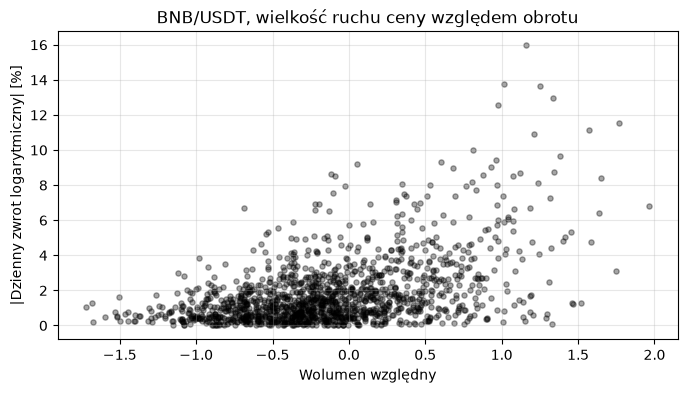

In [4]:
if "od 2023" in PERIODS:
    period = PERIODS["od 2023"]
    abs_ret = sm.returns(cut(data["BNBUSDT"]["close"], period), "log").abs()
    rel_vol = cut(sm.relative_volume(data["BNBUSDT"]["quote_volume"], 30), period)
    joined = pd.concat([abs_ret.rename("abs_ret"), rel_vol.rename("rel_vol")], axis=1, sort=True).dropna()
    if not joined.empty:
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.scatter(joined["rel_vol"], joined["abs_ret"] * 100, alpha=0.35, s=14, color="black")
        ax.set_xlabel("Wolumen względny")
        ax.set_ylabel("|Dzienny zwrot logarytmiczny| [%]")
        ax.set_title("BNB/USDT, wielkość ruchu ceny względem obrotu")
        ax.grid(alpha=0.3)
        plt.show()

Związek jest dodatni, zgodnie z oczekiwaniem z rozdziału 10: dni z obrotem wyższym niż w poprzednim miesiącu to zwykle dni z większymi ruchami ceny. Korelacja jest umiarkowana, więc obrót wyjaśnia tylko część wielkości ruchów. Korelacja nie mówi o kierunku zależności, czyli o tym, czy to duży ruch ceny przyciąga obrót, czy odwrotnie.

## 3. Wartości kontrolne dla aplikacji

Wyniki z dokładnością do 10 miejsc po przecinku, jako ułamki. Analiza wydarzeń dotyczy zamkniętych okresów w przeszłości, a okres kontrolny wolumenu to rok 2024, więc te wartości już się nie zmienią. Aplikacja liczona na tych samych danych powinna je odtworzyć do szóstej cyfry znaczącej.

In [5]:
def fmt(x):
    return "brak" if pd.isna(x) else f"{x:.10f}"


for _, row in summary.iterrows():
    print(f"{row['event_date']} {row['label']}, okno {row['window']}, dni estymacji {row['estimation_days']}")
    for key in ["asset_return", "market_return", "car", "car_alpha0", "se_car", "t", "p_value", "p_holm"]:
        print(f"    {key}: {fmt(row[key])}")
    print(f"    istotność: {row['significant']}")

if "rok 2024" in PERIODS:
    v = sm.volume_relation(cut(data["BNBUSDT"]["close"], PERIODS["rok 2024"]), data["BNBUSDT"]["quote_volume"])
    print(f"Wolumen, rok 2024: obserwacje {v['observations']}, Pearson {fmt(v['pearson'])}, Spearman {fmt(v['spearman'])}")

2023-03-27 Pozew CFTC, okno [-1, +1], dni estymacji 110
    asset_return: -0.0285359801
    market_return: -0.0073509947
    car: -0.0155891217
    car_alpha0: -0.0230986634
    se_car: 0.0323520107
    t: -0.4818594391
    p_value: 0.6308808305
    p_holm: 1.0000000000
    istotność: nieistotna
2023-03-27 Pozew CFTC, okno [-5, +5], dni estymacji 110
    asset_return: -0.0583133971
    market_return: 0.0123556020
    car: -0.0422882416
    car_alpha0: -0.0698232277
    se_car: 0.0640850034
    t: -0.6598773414
    p_value: 0.5107373475
    p_holm: 1.0000000000
    istotność: nieistotna
2023-06-05 Pozew SEC, okno [-1, +1], dni estymacji 99
    asset_return: -0.0828440965
    market_return: 0.0059425429
    car: -0.0874359239
    car_alpha0: -0.0903548201
    se_car: 0.0263710546
    t: -3.3156020974
    p_value: 0.0012873249
    p_holm: 0.0167352232
    istotność: istotna
2023-06-05 Pozew SEC, okno [-5, +5], dni estymacji 99
    asset_return: -0.2337078652
    market_return: -0.06691569